In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from adjustText import adjust_text

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'mesencoder', 'bifurcation', 'modules')

In [3]:
c_dict = {
    'Gast' : plt.cm.tab20c(12),
    'pSom' : plt.cm.tab20c(8),
    'Both' : 'darkgrey'}

In [4]:
# select genes: Gast | pSom
get_feat = lambda pth: pd.read_csv(pth).mmusculus.drop_duplicates()
g1 = get_feat(os.path.join(pth_feat, 'GSE162534.csv'))
g2 = get_feat(os.path.join(pth_feat, 'GSE229103.csv'))
g = pd.merge(g1, g2, 'outer').mmusculus

In [5]:
adata = sc.read_h5ad(os.path.join(pth_in, 'bifurcation.h5ad'))
adata = adata[:, g].copy(); adata

AnnData object with n_obs × n_vars = 11243 × 150
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'mesencoder'
    uns: 'celltype_colors'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [6]:
# select: early epiblast cells (only)
adata_epi = adata[adata.obs.celltype == 'Epiblast'].copy()
t = adata_epi.obs.t.copy()
adata_plt = adata_epi[t < t.median()].copy(); adata_plt

AnnData object with n_obs × n_vars = 1399 × 150
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'mesencoder'
    uns: 'celltype_colors'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [7]:
# compute gene-module correlations
X = pd.DataFrame(adata_plt.X.toarray(),
                 index = adata_plt.obs_names,
                 columns = adata.var_names)
X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
R = pd.DataFrame(index = X.columns)
mod1 = adata_plt.obs.GSE162534.values[:, None]
mod2 = adata_plt.obs.GSE229103.values[:, None]
R['Gast'] = pearsonr(X, mod1, axis = 0).statistic
R['pSom'] = pearsonr(X, mod2, axis = 0).statistic
rank = R.abs().sum(axis = 1).rank(ascending = False)
R = R.loc[rank.sort_values().index].copy()

# module labels
msk_dict = {
    'Gast' : R.index.isin(g1) & ~R.index.isin(g2),
    'pSom' : ~R.index.isin(g1) & R.index.isin(g2),
    'Both' : R.index.isin(g1) & R.index.isin(g2)}
for mod, msk in msk_dict.items():
    R.loc[msk, 'Module'] = mod
    print(mod, msk.sum())
R['Module'] = pd.Categorical(R.Module,
                             reversed(msk_dict.keys()),
                             ordered = True)

# mutual correlation
rval = np.corrcoef(*R.loc[(R.Module != 'Both'),
    ['Gast', 'pSom']].values.T)[0, 1].round(2)
print('r =', rval)

Gast 52
pSom 70
Both 27
r = -0.47


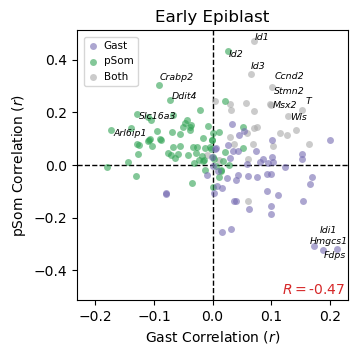

In [8]:
# plot correlations
fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
for mod, sdf in R.groupby('Module', observed = True):
    sdf.plot(kind = 'scatter', x = 'Gast', y = 'pSom',
             color = c_dict[mod], label = mod, s = 25,
             alpha = .6, linewidth = 0, ax = ax)
ax.axvline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
ax.axhline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
xlim = abs(np.asarray(ax.get_xlim())).max()
ylim = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)

# label top genes
texts = list()
for ix in R.head(15).index:
    texts.append(ax.text(
        R.loc[ix].Gast,
        R.loc[ix].pSom,
        ix, fontsize = 6.75,
        fontstyle = 'italic'))
adjust_text(texts = texts)

ax.legend(handlelength = 1,
          handletextpad = .5,
          borderaxespad = .65,
          fontsize = 7.5,
          reverse = True)

# mutual correlation
ax.text(.99, .01, r'$R=$' + f'{rval}',
        transform = ax.transAxes,
        fontsize = 10, color = 'tab:red',
        ha = 'right', va = 'bottom')

ax.set_title('Early Epiblast')
ax.set_xlabel(r'Gast Correlation ($r$)')
ax.set_ylabel(r'pSom Correlation ($r$)')
fn = os.path.join(pth_out, 'Epi_early.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [9]:
# select: late epiblast cells (only)
adata_plt = adata_epi[t > t.median()].copy()
adata_plt

AnnData object with n_obs × n_vars = 1399 × 150
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'mesencoder'
    uns: 'celltype_colors'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [10]:
# compute gene-module correlations
X = pd.DataFrame(adata_plt.X.toarray(),
                 index = adata_plt.obs_names,
                 columns = adata.var_names)
X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
R = pd.DataFrame(index = X.columns)
mod1 = adata_plt.obs.GSE162534.values[:, None]
mod2 = adata_plt.obs.GSE229103.values[:, None]
R['Gast'] = pearsonr(X, mod1, axis = 0).statistic
R['pSom'] = pearsonr(X, mod2, axis = 0).statistic
rank = R.abs().sum(axis = 1).rank(ascending = False)
R = R.loc[rank.sort_values().index].copy()

# module labels
msk_dict = {
    'Gast' : R.index.isin(g1) & ~R.index.isin(g2),
    'pSom' : ~R.index.isin(g1) & R.index.isin(g2),
    'Both' : R.index.isin(g1) & R.index.isin(g2)}
for mod, msk in msk_dict.items():
    R.loc[msk, 'Module'] = mod
    print(mod, msk.sum())
R['Module'] = pd.Categorical(R.Module,
                             reversed(msk_dict.keys()),
                             ordered = True)

# mutual correlation
rval = np.corrcoef(*R.loc[(R.Module != 'Both'),
    ['Gast', 'pSom']].values.T)[0, 1].round(2)
print('r =', rval)

Gast 52
pSom 70
Both 27
r = -0.09


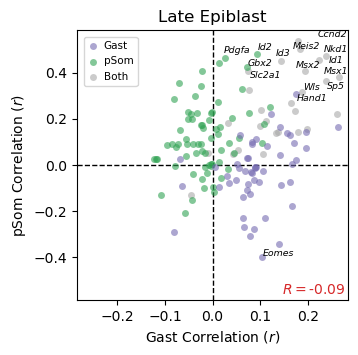

In [11]:
# plot correlations
fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
for mod, sdf in R.groupby('Module', observed = True):
    sdf.plot(kind = 'scatter', x = 'Gast', y = 'pSom',
             color = c_dict[mod], label = mod, s = 25,
             alpha = .6, linewidth = 0, ax = ax)
ax.axvline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
ax.axhline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
xlim = abs(np.asarray(ax.get_xlim())).max()
ylim = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)

# label top genes
texts = list()
for ix in R.head(15).index:
    texts.append(ax.text(
        R.loc[ix].Gast,
        R.loc[ix].pSom,
        ix, fontsize = 6.75,
        fontstyle = 'italic'))
adjust_text(texts = texts)

ax.legend(handlelength = 1,
          handletextpad = .5,
          borderaxespad = .65,
          fontsize = 7.5,
          reverse = True)

# mutual correlation
ax.text(.99, .01, r'$R=$' + f'{rval}',
        transform = ax.transAxes,
        fontsize = 10, color = 'tab:red',
        ha = 'right', va = 'bottom')

ax.set_title('Late Epiblast')
ax.set_xlabel(r'Gast Correlation ($r$)')
ax.set_ylabel(r'pSom Correlation ($r$)')
fn = os.path.join(pth_out, 'Epi_late.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [12]:
# select: neuromesodermal progenitors (only)
msk = (adata.obs.celltype == 'Neuromesodermal Progenitor')
adata_plt = adata[msk].copy(); adata_plt

AnnData object with n_obs × n_vars = 2516 × 150
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'mesencoder'
    uns: 'celltype_colors'
    obsm: 'X_feat', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [13]:
# compute gene-module correlations
X = pd.DataFrame(adata_plt.X.toarray(),
                 index = adata_plt.obs_names,
                 columns = adata.var_names)
X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
R = pd.DataFrame(index = X.columns)
mod1 = adata_plt.obs.GSE162534.values[:, None]
mod2 = adata_plt.obs.GSE229103.values[:, None]
R['Gast'] = pearsonr(X, mod1, axis = 0).statistic
R['pSom'] = pearsonr(X, mod2, axis = 0).statistic
rank = R.abs().sum(axis = 1).rank(ascending = False)
R = R.loc[rank.sort_values().index].copy()

# module labels
msk_dict = {
    'Gast' : R.index.isin(g1) & ~R.index.isin(g2),
    'pSom' : ~R.index.isin(g1) & R.index.isin(g2),
    'Both' : R.index.isin(g1) & R.index.isin(g2)}
for mod, msk in msk_dict.items():
    R.loc[msk, 'Module'] = mod
    print(mod, msk.sum())
R['Module'] = pd.Categorical(R.Module,
                             reversed(msk_dict.keys()),
                             ordered = True)

# mutual correlation
rval = np.corrcoef(*R.loc[(R.Module != 'Both'),
    ['Gast', 'pSom']].values.T)[0, 1].round(2)
print('r =', rval)

Gast 52
pSom 71
Both 27
r = 0.59


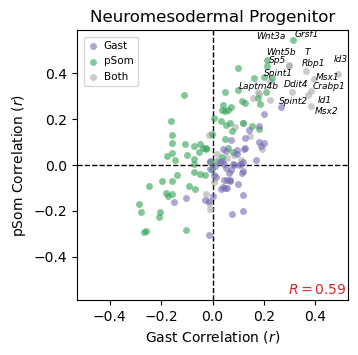

In [14]:
# plot correlations
fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
for mod, sdf in R.groupby('Module', observed = True):
    sdf.plot(kind = 'scatter', x = 'Gast', y = 'pSom',
             color = c_dict[mod], label = mod, s = 25,
             alpha = .6, linewidth = 0, ax = ax)
ax.axvline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
ax.axhline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
xlim = abs(np.asarray(ax.get_xlim())).max()
ylim = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)

# label top genes
texts = list()
for ix in R.head(15).index:
    texts.append(ax.text(
        R.loc[ix].Gast,
        R.loc[ix].pSom,
        ix, fontsize = 6.5,
        fontstyle = 'italic'))
adjust_text(texts = texts)

ax.legend(handlelength = 1,
          handletextpad = .5,
          borderaxespad = .65,
          fontsize = 7.5,
          reverse = True)

# mutual correlation
ax.text(.99, .01, r'$R=$' + f'{rval}',
        transform = ax.transAxes,
        fontsize = 10, color = 'tab:red',
        ha = 'right', va = 'bottom')

ax.set_title('Neuromesodermal Progenitor')
ax.set_xlabel(r'Gast Correlation ($r$)')
ax.set_ylabel(r'pSom Correlation ($r$)')
fn = os.path.join(pth_out, 'NMP.pdf')
plt.savefig(fn, bbox_inches = 'tight')